In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("Searching for Dataset_OCR...\n")

for root, dirs, files in os.walk("/content/drive"):
    if "Dataset_OCR" in dirs:
        dataset_path = os.path.join(root, "Dataset_OCR")
        print("FOUND ✅")
        print("Dataset path:")
        print(dataset_path)
        break
else:
    print("Dataset_OCR folder not found ❌")

Searching for Dataset_OCR...

FOUND ✅
Dataset path:
/content/drive/MyDrive/Dataset_OCR


In [ ]:
import os

print("Searching for Dataset_OCR...\n")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "Dataset_OCR" in dirs:
        dataset_path = os.path.join(root, "Dataset_OCR")
        print("FOUND ✅")
        print("Dataset path:")
        print(dataset_path)
        break
else:
    print("Dataset_OCR folder not found ❌")

Searching for Dataset_OCR...

FOUND ✅
Dataset path:
/content/drive/MyDrive/Dataset_OCR


In [ ]:
import os

image_files = [
    f for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images:", len(image_files))

print("\nFirst 10 images:")
for f in image_files[:10]:
    print(f)

Total images: 100

First 10 images:
thyrocare_0_5879.jpg
thyrocare_0_9575.jpg
thyrocare_0_7758.jpg
thyrocare_0_517.jpg
thyrocare_0_7571.jpg
thyrocare_0_2691.jpg
thyrocare_0_1248.jpg
thyrocare_0_5338.jpg
thyrocare_0_8748.jpg
thyrocare_0_4790.jpg


Image name: thyrocare_0_5879.jpg
Image size: (939, 631)


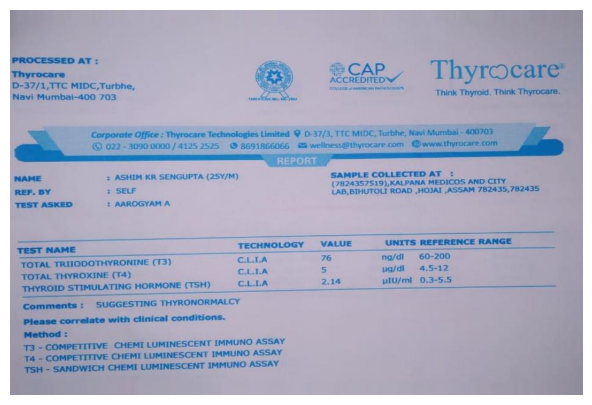

In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt

sample_image = os.path.join(dataset_path, image_files[0])

img = Image.open(sample_image)

print("Image name:", image_files[0])
print("Image size:", img.size)

plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


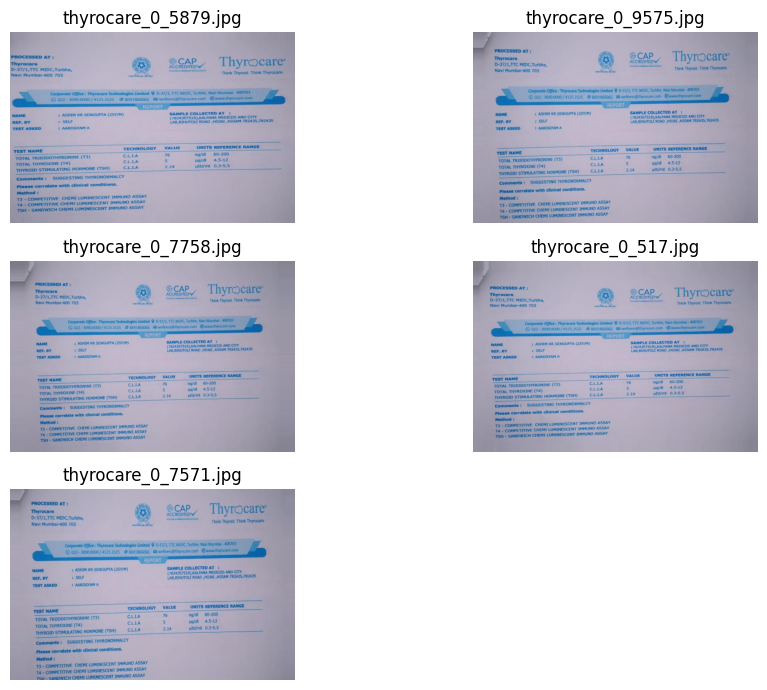

In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt

sample_files = image_files[:5]

plt.figure(figsize=(10, 7))

for i, filename in enumerate(sample_files):
    img_path = os.path.join(dataset_path, filename)
    img = Image.open(img_path)

    plt.subplot(3, 2, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

# YOLO project folders
yolo_path = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

folders = [
    "images",
    "labels",
    "train",
    "val",
    "test",
    "model",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(yolo_path, folder), exist_ok=True)

# YOLO class names
classes = [
    "patient_details",
    "test_name",
    "value",
    "units",
    "reference_range"
]

classes_file = os.path.join(yolo_path, "classes.txt")

with open(classes_file, "w") as f:
    for cls in classes:
        f.write(cls + "\n")

print("YOLO project folders created successfully ✅")
print("\nClasses:")
for i, cls in enumerate(classes):
    print(i, "=", cls)

print("\nProject path:")
print(yolo_path)

YOLO project folders created successfully ✅

Classes:
0 = patient_details
1 = test_name
2 = value
3 = units
4 = reference_range

Project path:
/content/drive/MyDrive/Custom_OCR_YOLOv3


In [ ]:
import shutil
import os

source_folder = dataset_path
target_folder = os.path.join(yolo_path, "images")

image_files = [
    f for f in os.listdir(source_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

for filename in image_files:
    source = os.path.join(source_folder, filename)
    target = os.path.join(target_folder, filename)
    shutil.copy2(source, target)

print("Images copied successfully ✅")
print("Total images copied:", len(image_files))
print("Destination:", target_folder)

Images copied successfully ✅
Total images copied: 100
Destination: /content/drive/MyDrive/Custom_OCR_YOLOv3/images


Image: thyrocare_0_5879.jpg
Size: (939, 631)


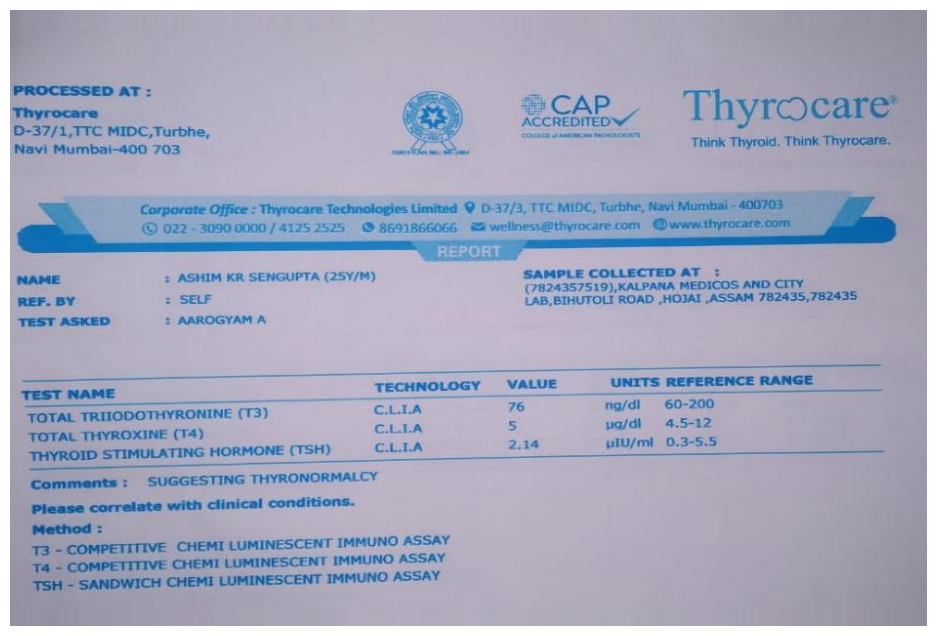

In [ ]:
# Check first image in our YOLO folder

import os
from PIL import Image
import matplotlib.pyplot as plt

first_image = os.path.join(yolo_path, "images", image_files[0])

img = Image.open(first_image)

print("Image:", image_files[0])
print("Size:", img.size)

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
import shutil

source = "/content/drive/MyDrive/Custom_OCR_YOLOv3/images"
zip_path = "/content/Custom_OCR_YOLOv3_images"

shutil.make_archive(zip_path, "zip", source)

print("ZIP ready ✅")
print(zip_path + ".zip")

ZIP ready ✅
/content/Custom_OCR_YOLOv3_images.zip


In [ ]:
from google.colab import files

files.download("/content/Custom_OCR_YOLOv3_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os

project_path = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

print("Project folder exists:", os.path.exists(project_path))

if os.path.exists(project_path):
    for item in os.listdir(project_path):
        print(item)
else:
    print("Project folder not found. Check Google Drive mounting.")


Project folder exists: True
images
labels
train
val
test
model
results
classes.txt


In [ ]:

import os

base = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

for folder in ["images", "labels", "train", "val", "test", "model", "results"]:
    path = os.path.join(base, folder)
    print(f"\n--- {folder} ---")
    if os.path.isdir(path):
        items = os.listdir(path)
        print("Total files:", len(items))
        print("First 10:", items[:10])
    else:
        print("Folder missing")

print("\n--- classes.txt ---")
with open(os.path.join(base, "classes.txt"), "r") as f:
    print(f.read())



--- images ---
Total files: 100
First 10: ['thyrocare_0_9575.jpg', 'thyrocare_0_7758.jpg', 'thyrocare_0_5879.jpg', 'thyrocare_0_1248.jpg', 'thyrocare_0_5338.jpg', 'thyrocare_0_7571.jpg', 'thyrocare_0_2691.jpg', 'thyrocare_0_4790.jpg', 'thyrocare_0_8748.jpg', 'thyrocare_0_640.jpg']

--- labels ---
Total files: 0
First 10: []

--- train ---
Total files: 0
First 10: []

--- val ---
Total files: 0
First 10: []

--- test ---
Total files: 0
First 10: []

--- model ---
Total files: 0
First 10: []

--- results ---
Total files: 0
First 10: []

--- classes.txt ---
patient_details
test_name
value
units
reference_range



In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

base = "/content/drive/MyDrive"

for name in os.listdir(base):
    if "OCR" in name.upper() or "YOLO" in name.upper():
        print(name)


Dataset_OCR
Custom_OCR_YOLOv3


In [ ]:

import os

project = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

for root, dirs, files in os.walk(project):
    level = root.replace(project, "").count(os.sep)
    if level > 2:
        dirs[:] = []
    print("  " * level + os.path.basename(root) + "/")
    for f in files[:10]:
        print("  " * (level + 1) + f)


Custom_OCR_YOLOv3/
  classes.txt
  images/
    thyrocare_0_9575.jpg
    thyrocare_0_7758.jpg
    thyrocare_0_5879.jpg
    thyrocare_0_1248.jpg
    thyrocare_0_5338.jpg
    thyrocare_0_7571.jpg
    thyrocare_0_2691.jpg
    thyrocare_0_4790.jpg
    thyrocare_0_8748.jpg
    thyrocare_0_640.jpg
  labels/
  train/
  val/
  test/
  model/
  results/


In [ ]:

import os

base = "/content/drive/MyDrive"
extensions = (".json", ".xml", ".csv", ".txt", ".zip")

print("Searching for annotation/export files...\n")

for root, dirs, files in os.walk(base):
    # Skip common large/unrelated folders
    dirs[:] = [d for d in dirs if d not in
               ["node_modules", ".git", "__pycache__"]]

    for f in files:
        if f.lower().endswith(extensions):
            if any(word in f.lower() for word in
                   ["label", "annot", "export", "task", "yolo", "thyrocare"]):
                print(os.path.join(root, f))


Searching for annotation/export files...



In [ ]:

import shutil

shutil.make_archive(
    "/content/Custom_OCR_YOLOv3_images",
    "zip",
    "/content/drive/MyDrive/Custom_OCR_YOLOv3/images"
)

from google.colab import files
files.download("/content/Custom_OCR_YOLOv3_images.zip")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

project = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

for folder in ["images", "labels", "train", "val", "test", "model", "results"]:
    path = os.path.join(project, folder)
    os.makedirs(path, exist_ok=True)
    print(folder, ":", len(os.listdir(path)), "files")

images : 100 files
labels : 0 files
train : 0 files
val : 0 files
test : 0 files
model : 0 files
results : 0 files


In [ ]:
import os
import random
import shutil

project = "/content/drive/MyDrive/Custom_OCR_YOLOv3"
images_dir = os.path.join(project, "images")

random.seed(42)

images = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.shuffle(images)

train_end = int(len(images) * 0.8)
val_end = int(len(images) * 0.9)

splits = {
    "train": images[:train_end],
    "val": images[train_end:val_end],
    "test": images[val_end:]
}

for split, files in splits.items():
    split_dir = os.path.join(project, split, "images")
    os.makedirs(split_dir, exist_ok=True)

    for filename in files:
        src = os.path.join(images_dir, filename)
        dst = os.path.join(split_dir, filename)
        shutil.copy2(src, dst)

    print(f"{split}: {len(files)} images")

print("Dataset split completed.")

train: 80 images
val: 10 images
test: 10 images
Dataset split completed.


In [ ]:
import os

project = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

yaml_content = """path: /content/drive/MyDrive/Custom_OCR_YOLOv3
train: train/images
val: val/images
test: test/images

names:
  0: patient_details
  1: test_name
  2: value
  3: units
  4: reference_range
"""

yaml_path = os.path.join(project, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("Created:", yaml_path)
print(open(yaml_path).read())

Created: /content/drive/MyDrive/Custom_OCR_YOLOv3/data.yaml
path: /content/drive/MyDrive/Custom_OCR_YOLOv3
train: train/images
val: val/images
test: test/images

names:
  0: patient_details
  1: test_name
  2: value
  3: units
  4: reference_range



In [ ]:

!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract opencv-python-headless


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import pytesseract
import cv2

print("Tesseract version:", pytesseract.get_tesseract_version())
print("OpenCV version:", cv2.__version__)

Tesseract version: 5.3.4
OpenCV version: 4.14.0


In [ ]:

import cv2
import pytesseract
import torch
import os

print("OpenCV:", cv2.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

project_path = "/content/drive/MyDrive/Custom_OCR_YOLOv3"
print("Project Folder Exists:", os.path.exists(project_path))
print("Project Files:", os.listdir(project_path))


OpenCV: 4.14.0
Tesseract: 5.3.4
PyTorch: 2.11.0+cu130
CUDA Available: True
Project Folder Exists: True
Project Files: ['images', 'labels', 'train', 'val', 'test', 'model', 'results', 'classes.txt', 'data.yaml']


In [ ]:

import os
import yaml

project_path = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

with open(os.path.join(project_path, "data.yaml"), "r") as f:
    data = yaml.safe_load(f)

print("Dataset Configuration:")
print(data)

for folder in ["images/train", "images/val", "images/test",
               "labels/train", "labels/val", "labels/test"]:
    path = os.path.join(project_path, folder)
    if os.path.exists(path):
        print(f"{folder}: {len(os.listdir(path))} files")
    else:
        print(f"{folder}: Folder NOT FOUND")


Dataset Configuration:
{'path': '/content/drive/MyDrive/Custom_OCR_YOLOv3', 'train': 'train/images', 'val': 'val/images', 'test': 'test/images', 'names': {0: 'patient_details', 1: 'test_name', 2: 'value', 3: 'units', 4: 'reference_range'}}
images/train: Folder NOT FOUND
images/val: Folder NOT FOUND
images/test: Folder NOT FOUND
labels/train: Folder NOT FOUND
labels/val: Folder NOT FOUND
labels/test: Folder NOT FOUND


In [ ]:

import os

project_path = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

for folder in ["train", "val", "test", "images", "labels"]:
    path = os.path.join(project_path, folder)

    print(f"\n--- {folder} ---")

    if os.path.exists(path):
        print("Contents:", os.listdir(path)[:15])

        for root, dirs, files in os.walk(path):
            level = root.replace(path, "").count(os.sep)
            if level < 2:
                print("  " * level, os.path.basename(root) or folder,
                      "| Files:", len(files))
    else:
        print("Folder NOT FOUND")



--- train ---
Contents: ['images']
 train | Files: 0
   images | Files: 80

--- val ---
Contents: ['images']
 val | Files: 0
   images | Files: 10

--- test ---
Contents: ['images']
 test | Files: 0
   images | Files: 10

--- images ---
Contents: ['thyrocare_0_9575.jpg', 'thyrocare_0_7758.jpg', 'thyrocare_0_5879.jpg', 'thyrocare_0_1248.jpg', 'thyrocare_0_5338.jpg', 'thyrocare_0_7571.jpg', 'thyrocare_0_2691.jpg', 'thyrocare_0_4790.jpg', 'thyrocare_0_8748.jpg', 'thyrocare_0_640.jpg', 'thyrocare_0_8749.jpg', 'thyrocare_0_517.jpg', 'thyrocare_0_3439.jpg', 'thyrocare_0_7601.jpg', 'thyrocare_0_4468.jpg']
 images | Files: 100

--- labels ---
Contents: []
 labels | Files: 0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("\nProject files:")

for item in os.listdir(PROJECT_DIR):
    print(item)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project exists: True

Project files:
images
labels
train
val
test
model
results
classes.txt
data.yaml


In [ ]:
import os
import glob
import zipfile

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

# Project folder madhil ZIP files shodha
zip_files = glob.glob(os.path.join(PROJECT_DIR, "*.zip"))

print("ZIP files found:", zip_files)

if zip_files:
    zip_path = zip_files[-1]
    extract_dir = os.path.join(PROJECT_DIR, "label_studio_export")
    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

    print("\nZIP extracted successfully!")
    print("Extract folder:", extract_dir)

    for root, dirs, files in os.walk(extract_dir):
        for file in files[:10]:
            print(os.path.join(root, file))
else:
    print("ZIP file project folder madhye sapadli nahi.")

ZIP files found: []
ZIP file project folder madhye sapadli nahi.


In [ ]:

import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"

print("PROJECT EXISTS:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    for folder in ["images", "train/images", "val/images",
                   "test/images", "labels", "model", "results"]:
        path = os.path.join(PROJECT_DIR, folder)
        if os.path.isdir(path):
            files = os.listdir(path)
            print(f"{folder}: {len(files)} files")
        else:
            print(f"{folder}: NOT FOUND")

    print("\nZIP FILES:")
    for f in glob.glob("/content/drive/MyDrive/**/*.zip",
                       recursive=True):
        print(f)

    print("\nLABEL TXT FILES:")
    for f in glob.glob(PROJECT_DIR + "/**/*.txt",
                       recursive=True):
        if "/labels/" in f.replace("\\", "/"):
            print(f)


PROJECT EXISTS: True
images: NOT FOUND
train/images: NOT FOUND
val/images: NOT FOUND
test/images: NOT FOUND
labels: NOT FOUND
model: NOT FOUND
results: NOT FOUND

ZIP FILES:
/content/drive/MyDrive/Assignment 1 - Data Analysis.zip
/content/drive/MyDrive/Custom_OCR_YOLOv3_images (7).zip

LABEL TXT FILES:


In [ ]:

import os
import zipfile

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"
ZIP_PATH = "/content/drive/MyDrive/Custom_OCR_YOLOv3_images (7).zip"

print("PROJECT FOLDER CONTENTS:")
print(os.listdir(PROJECT_DIR))

print("\nZIP CONTENTS:")
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()
    print("Total files:", len(files))
    for name in files[:25]:
        print(name)

    label_files = [
        name for name in files
        if name.lower().endswith(".txt")
        and "label" in name.lower()
    ]
    print("\nPossible label files:", label_files[:20])


PROJECT FOLDER CONTENTS:
[]

ZIP CONTENTS:
Total files: 100
thyrocare_0_9575.jpg
thyrocare_0_7758.jpg
thyrocare_0_5879.jpg
thyrocare_0_1248.jpg
thyrocare_0_5338.jpg
thyrocare_0_7571.jpg
thyrocare_0_2691.jpg
thyrocare_0_4790.jpg
thyrocare_0_8748.jpg
thyrocare_0_640.jpg
thyrocare_0_8749.jpg
thyrocare_0_517.jpg
thyrocare_0_3439.jpg
thyrocare_0_7601.jpg
thyrocare_0_4468.jpg
thyrocare_0_912.jpg
thyrocare_0_3804.jpg
thyrocare_0_7219.jpg
thyrocare_0_9108.jpg
thyrocare_0_1433.jpg
thyrocare_0_5074.jpg
thyrocare_0_8214.jpg
thyrocare_0_4683.jpg
thyrocare_0_3333.jpg
thyrocare_0_9447.jpg

Possible label files: []


In [ ]:

import os
import zipfile
import random
import shutil

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"
ZIP_PATH = "/content/drive/MyDrive/Custom_OCR_YOLOv3_images (7).zip"

# Create project folders
for folder in [
    "images", "train/images", "train/labels",
    "val/images", "val/labels",
    "test/images", "test/labels",
    "model", "results"
]:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

# Extract the 100 original images
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    image_names = [
        n for n in z.namelist()
        if n.lower().endswith((".jpg", ".jpeg", ".png"))
        and "/" not in n
    ]

    for name in image_names:
        destination = os.path.join(PROJECT_DIR, "images", name)
        with z.open(name) as src, open(destination, "wb") as dst:
            shutil.copyfileobj(src, dst)

# Split images: 80% train, 10% validation, 10% test
random.seed(42)
random.shuffle(image_names)

train_files = image_names[:80]
val_files = image_names[80:90]
test_files = image_names[90:100]

for split, files in [
    ("train", train_files),
    ("val", val_files),
    ("test", test_files)
]:
    for name in files:
        src = os.path.join(PROJECT_DIR, "images", name)
        dst = os.path.join(PROJECT_DIR, split, "images", name)
        shutil.copy2(src, dst)

# Create dataset configuration
yaml_text = f"""path: {PROJECT_DIR}
train: train/images
val: val/images
test: test/images
names:
  0: patient_details
  1: test_name
  2: value
  3: units
  4: reference_range
"""

with open(os.path.join(PROJECT_DIR, "data.yaml"), "w") as f:
    f.write(yaml_text)

print("Project setup complete!")
print("Original images:", len(image_names))
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))
print("Dataset config saved.")


Project setup complete!
Original images: 100
Training images: 80
Validation images: 10
Test images: 10
Dataset config saved.


In [ ]:

import os
import cv2
import pytesseract
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

PROJECT_DIR = "/content/drive/MyDrive/Custom_OCR_YOLOv3"
IMAGE_DIR = os.path.join(PROJECT_DIR, "images")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

image_files = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

results = []

for filename in tqdm(sorted(image_files)):
    image_path = os.path.join(IMAGE_DIR, filename)

    image = cv2.imread(image_path)

    if image is None:
        results.append({
            "image": filename,
            "extracted_text": "",
            "status": "Image read failed"
        })
        continue

    # Preprocess image to improve text recognition
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(
        gray, None, fx=1.5, fy=1.5,
        interpolation=cv2.INTER_CUBIC
    )
    processed = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    try:
        extracted_text = pytesseract.image_to_string(
            processed,
            config="--oem 3 --psm 6"
        )

        results.append({
            "image": filename,
            "extracted_text": extracted_text.strip(),
            "status": "success" if extracted_text.strip() else "No text detected"
        })

    except Exception as e:
        results.append({
            "image": filename,
            "extracted_text": "",
            "status": f"Error: {e}"
        })

df = pd.DataFrame(results)

csv_path = os.path.join(RESULTS_DIR, "ocr_results.csv")
df.to_csv(csv_path, index=False)

print("\nOCR completed!")
print("Images processed:", len(df))
print("Text detected:", (df["status"] == "success").sum())
print("Results saved:", csv_path)

print("\nSample OCR output:")
print(df.iloc[0]["extracted_text"][:2000])


ModuleNotFoundError: No module named 'pytesseract'